# code_006 · One small building, several useful representations

**Book:** Chapter 1, section 1.5. **Purpose:** executable concept experiments, not a complete estimator hyperparameter course. All data and helper definitions are inside this notebook. Synthetic values are invented for teaching and provide no engineering validation.

Use the repository [quickstart](../README.md) and pinned environment. Restart the kernel and run all cells in order. Verified target: CPython 3.14.3 and scikit-learn 1.9.0, CPU only; no files, downloads, API keys or project imports are needed during execution. Allow a minute for execution plus time to reason through the prompts. Actual time, environment and checks are recorded at the end and in the [Chapter 1 execution report](../CHAPTER_01_EXECUTION.md).

Read each prediction prompt before running its experiment. Controls are identified as task, data-generation, model or decision controls; they are not interchangeable. The [stable directory](../CODE_EXAMPLES.md#code_006) links this example to the manuscript.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=101
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,
'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
assert sklearn.__version__=='1.9.0','Use the verified pinned environment.'
print(VERSIONS);print('CPU:',platform.system(),platform.machine())
plt.rcParams.update({'figure.dpi':100,'font.size':11,'axes.spines.top':False,
'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64


<a id="linked-tables"></a>
## Preserve entities before flattening

We define four synthetic members, three physical connection edges, two sensors per member and six ordered readings per sensor. Coordinates are in metres; load features in newtons. These are small invented records, not a complete structural model. A member is not the same unit as a sensor reading. Joining every reading to every member can amplify rows without adding independent members.

**Predict:** how many rows should a member-to-sensor join produce? How many after adding six readings? We validate keys and cardinality, then aggregate only when the question calls for a member-level summary. IDs are relational keys, not justified predictors by themselves.


In [2]:
members=pd.DataFrame({'member':['M1','M2','M3','M4'],'x_m':[0.,1.,1.,2.],'y_m':[0.,0.,1.,1.],'load_N':[100.,200.,150.,250.]})
edges=pd.DataFrame({'source':['M1','M2','M3'],'target':['M2','M3','M4']})
sensors=pd.DataFrame({'sensor':[f'S{i}' for i in range(8)],'member':np.repeat(members.member,2)})
assert members.member.is_unique and sensors.sensor.is_unique
joined=members.merge(sensors,on='member',validate='one_to_many')
assert len(joined)==8 and joined.member.nunique()==4
readings=pd.DataFrame([{'sensor':name,'slot':t,'summary':float(([0,0,0,1,1,1] if i%2==0 else [1,1,1,0,0,0])[t])}
 for i,name in enumerate(sensors.sensor) for t in range(6)])
reading_view=sensors.merge(readings,on='sensor',validate='one_to_many')
assert len(reading_view)==48 and reading_view.member.nunique()==4
assert not readings.duplicated(['sensor','slot']).any()
display(members);display(edges);display(sensors);display(readings.head(8))
RESULTS['entity_counts']={'members':len(members),'sensors':len(sensors),'physical_edges':len(edges),'joined_rows':len(joined),'readings':len(readings)}


,member,x_m,y_m,load_N
0,M1,0.0,0.0,100.0
1,M2,1.0,0.0,200.0
2,M3,1.0,1.0,150.0
3,M4,2.0,1.0,250.0


,source,target
0,M1,M2
1,M2,M3
2,M3,M4


,sensor,member
0,S0,M1
0,S1,M1
1,S2,M2
1,S3,M2
2,S4,M3
2,S5,M3
3,S6,M4
3,S7,M4


,sensor,slot,summary
0,S0,0,0.0
1,S0,1,0.0
2,S0,2,0.0
3,S0,3,1.0
4,S0,4,1.0
5,S0,5,1.0
6,S1,0,1.0
7,S1,1,1.0


<a id="graph"></a>
## Graph information survives a consistent reordering

An adjacency matrix records which members exchange messages. We use an undirected, unweighted physical connection relation, with zero diagonal. Multiplying adjacency by load sums neighbouring loads; it is a transparent relational feature, not a GNN or an equilibrium solver. Reordering member rows requires reordering both axes of adjacency. The result should correspond to the same labelled members after undoing the permutation.

**Predict:** can a table of isolated member loads recover which neighbours belong to M2 if the edges are discarded? Equal feature rows in two different topologies can have different neighbour context. Spatial proximity alone is also not proof of a physical connection.


,M1,M2,M3,M4
M1,0,1,0,0
M2,1,0,1,0
M3,0,1,0,1
M4,0,0,1,0


,member,own_load_N,neighbour_sum_N
0,M1,100.0,200.0
1,M2,200.0,250.0
2,M3,150.0,450.0
3,M4,250.0,150.0


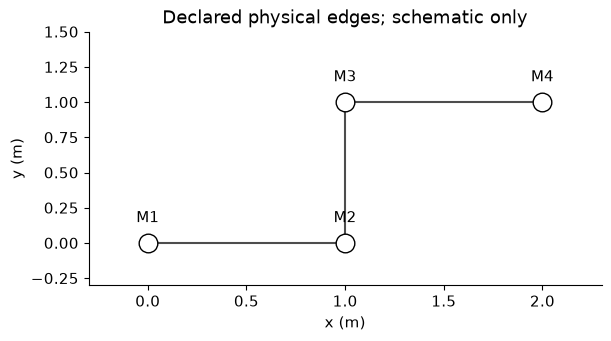

In [3]:
labels=members.member.tolist();lookup={name:i for i,name in enumerate(labels)}
A=np.zeros((4,4),dtype=int)
for row in edges.itertuples(index=False):
 i,j=lookup[row.source],lookup[row.target];A[i,j]=A[j,i]=1
loads=members.load_N.to_numpy();neighbour_load=A@loads
assert np.array_equal(A,A.T) and np.all(np.diag(A)==0)
perm=np.array([2,0,3,1]);inv=np.argsort(perm)
reordered=A[np.ix_(perm,perm)]@loads[perm]
assert np.array_equal(reordered[inv],neighbour_load)
display(pd.DataFrame(A,index=labels,columns=labels))
display(pd.DataFrame({'member':labels,'own_load_N':loads,'neighbour_sum_N':neighbour_load}))
fig,ax=plt.subplots(figsize=(6,3.3))
for row in edges.itertuples(index=False):
 pts=members.set_index('member').loc[[row.source,row.target]];ax.plot(pts.x_m,pts.y_m,color='.3')
ax.scatter(members.x_m,members.y_m,s=180,facecolor='white',edgecolor='black',zorder=3)
for row in members.itertuples():ax.annotate(row.member,(row.x_m,row.y_m),xytext=(0,15),textcoords='offset points',ha='center')
ax.set(xlabel='x (m)',ylabel='y (m)',title='Declared physical edges; schematic only',xlim=(-.3,2.3),ylim=(-.3,1.5));plt.show()
RESULTS['neighbour_loads_N']=neighbour_load.tolist()


<a id="time-and-resources"></a>
## A summary can erase the ordering needed for the task

Two sequences can have the same mean and variance but different recent behaviour. We construct increasing and decreasing six-step sensor summaries to make this loss explicit. Window length is a representation/data control, not pretraining. A full temporal learning task also needs timestamps, availability, prediction horizon and a valid temporal evaluation boundary.

The reading-map worksheet separates task, representation, model family, training objective and adaptation. Preprocessing changes input handling; pretraining fits a reusable model on prior tasks/data. A transformer architecture can be used with several objectives and task families, so these labels do not form exclusive boxes. **Predict:** does changing a dataframe into a graph automatically justify a GNN?


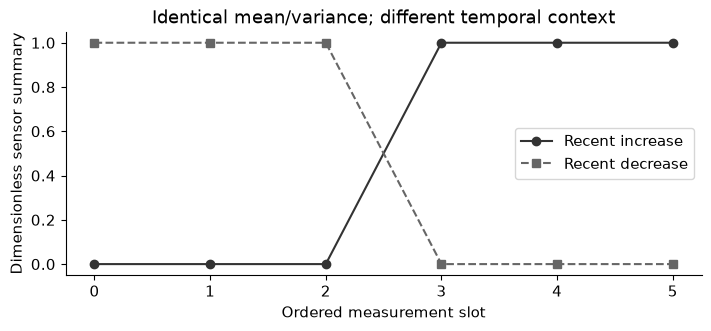

,task,representation,starting method,objective,adaptation_or_training
0,member risk,table + joins,linear/tree baseline,supervised classification,fit on development data
1,connected-member context,graph,aggregation before GNN,node/edge/graph objective,task-specific fitting
2,future sensor response,ordered sequence,seasonal/lag baseline,forecasting,fit or adapt pretrained model
3,load to displacement field,geometry + physical fields,reference solver,forward simulation,surrogate fitting if justified
4,inspection allocation,state + actions,cost rule/planning,decision utility,policy learning only if needed


,operation,role
0,check measurement units,data validity
1,fit median on training rows,preprocessing
2,train a reusable encoder on prior tasks,pretraining
3,supply labelled context with frozen weights,context adaptation
4,update pretrained weights on the new task,fine-tuning


Dense adjacency storage for this four-member example: 128 bytes


In [4]:
up=readings.loc[readings.sensor=='S0'].sort_values('slot').summary.to_numpy()
down=readings.loc[readings.sensor=='S1'].sort_values('slot').summary.to_numpy()
assert up.mean()==down.mean() and up.var()==down.var() and up[-1]!=down[-1]
fig,ax=plt.subplots(figsize=(7,3.2));ax.plot(up,'o-',color='.2',label='Recent increase');ax.plot(down,'s--',color='.4',label='Recent decrease')
ax.set(xlabel='Ordered measurement slot',ylabel='Dimensionless sensor summary',title='Identical mean/variance; different temporal context');ax.legend();plt.show()
route=pd.DataFrame([
 ['member risk','table + joins','linear/tree baseline','supervised classification','fit on development data'],
 ['connected-member context','graph','aggregation before GNN','node/edge/graph objective','task-specific fitting'],
 ['future sensor response','ordered sequence','seasonal/lag baseline','forecasting','fit or adapt pretrained model'],
 ['load to displacement field','geometry + physical fields','reference solver','forward simulation','surrogate fitting if justified'],
 ['inspection allocation','state + actions','cost rule/planning','decision utility','policy learning only if needed']],
 columns=['task','representation','starting method','objective','adaptation_or_training'])
display(route)
operations=pd.DataFrame([
 ['check measurement units','data validity'],['fit median on training rows','preprocessing'],
 ['train a reusable encoder on prior tasks','pretraining'],['supply labelled context with frozen weights','context adaptation'],
 ['update pretrained weights on the new task','fine-tuning']],columns=['operation','role'])
assert operations.loc[operations.operation.str.contains('median'),'role'].item()=='preprocessing'
assert operations.loc[operations.operation.str.contains('reusable encoder'),'role'].item()=='pretraining'
display(operations)
print('Dense adjacency storage for this four-member example:',A.nbytes,'bytes')
RESULTS['resource_reference']={'dense_adjacency_bytes':int(A.nbytes),'reading_rows':len(readings),'device':'CPU'}
RESULTS['same_summary_different_order']={'mean':float(up.mean()),'variance':float(up.var()),'last_up':float(up[-1]),'last_down':float(down[-1])}


## Exercises and a feasible first project

1. Create two different edge lists on the same member table and compare neighbour loads. Explain which physical record would decide the correct list.
2. Add a third sensor per member and demonstrate the additional row multiplication with cardinality assertions before aggregation.
3. Choose a one-week task, a simple baseline, one appropriate split, a metric and a CPU/time budget. State one condition that would justify a more complex representation.
4. Map one pretrained tabular model across architecture, objective, labelled context and weight adaptation. Explain why pretraining is not missing-value cleaning.
5. For each reading-map row, list one domain-validity check and one information-availability check.

**Optional hint:** a useful representation preserves what the question needs and can be built at decision time. More rows, a more complex architecture or reusable pretraining do not remove the need for valid data, baselines and evaluation.


## Interpretation, limits and next steps

The printed tables and figures are observations from this executed synthetic experiment. Describe the mechanism they demonstrate before comparing individual numbers. Fixed seeds make the teaching run reproducible; they do not establish performance in a new population. No deployment or physical validity guarantee follows from passing these checks. For model-specific controls, use the official documentation and the later model chapters; [code_001](../CODE_EXAMPLES.md#code_001) is a full decision-tree parameter laboratory.

**Troubleshooting:** a version assertion means the selected kernel differs from the pinned environment. Restart and run all cells rather than borrowing state from a different notebook. Missing or repeated timestamps require an explicit observation policy, not a silent row reorder. When adapting an experiment, record its new assumptions, selection rule and untouched assessment evidence. Initial package installation may use the internet; these cells do not.


In [5]:
EXECUTION_SUMMARY={'example_id':'code_006','versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU',
 'seed':SEED,'concepts_demonstrated':['tabular entities', 'relational keys and cardinality', 'graph adjacency and permutation', 'spatial coordinates', 'temporal order versus summaries', 'task architecture objective adaptation', 'baseline-first resource plan'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:',json.dumps(EXECUTION_SUMMARY,sort_keys=True))


EXECUTION_SUMMARY_JSON: {"concepts_demonstrated": ["tabular entities", "relational keys and cardinality", "graph adjacency and permutation", "spatial coordinates", "temporal order versus summaries", "task architecture objective adaptation", "baseline-first resource plan"], "elapsed_seconds": 0.12, "example_id": "code_006", "hardware": "Darwin arm64 CPU", "results": {"entity_counts": {"joined_rows": 8, "members": 4, "physical_edges": 3, "readings": 48, "sensors": 8}, "neighbour_loads_N": [200.0, 250.0, 450.0, 150.0], "resource_reference": {"dense_adjacency_bytes": 128, "device": "CPU", "reading_rows": 48}, "same_summary_different_order": {"last_down": 0.0, "last_up": 1.0, "mean": 0.5, "variance": 0.25}}, "seed": 101, "versions": {"matplotlib": "3.11.0", "numpy": "2.4.4", "pandas": "3.0.3", "python": "3.14.3", "scikit-learn": "1.9.0", "scipy": "1.17.1"}}
